## DS2023 Project 2

### Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets
from ipywidgets import interact

### Load Data

In [3]:
#Loading in data
#Check for missing values is in looking_at_data_options.ipynb


living_cases = pd.read_csv("persons-living-with-hiv-aids.csv")
new_cases = pd.read_csv("persons-newly-diagnosed-with-hiv.csv")
deaths = pd.read_csv("deaths-of-persons-diagnosed-with-hiv-aids.csv")

df1 = living_cases.rename(columns={'Count': 'Count_Living'})
df2 = new_cases.rename(columns={'Count': 'Count_New'})
df3 = deaths.rename(columns={'Count': 'Count_Deaths'})

combined = (
    df1
    .merge(df2, on=['Year', 'Category', 'Group'])
    .merge(df3, on=['Year', 'Category', 'Group'])
)

combined.head(10)
combined.info()

<class 'pandas.DataFrame'>
RangeIndex: 658 entries, 0 to 657
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   Year          658 non-null    int64
 1   Category      658 non-null    str  
 2   Group         658 non-null    str  
 3   Count_Living  658 non-null    int64
 4   Count_New     658 non-null    int64
 5   Count_Deaths  658 non-null    int64
dtypes: int64(4), str(2)
memory usage: 31.0 KB


In [7]:
#rates per 1,000 people living with HIV, so groups of different sizes can be compared
combined['Death_Rate'] = combined.Count_Deaths / combined.Count_Living * 1000
combined['Diagnosis_Rate'] = combined.Count_New / combined.Count_Living * 1000
combined.head()

,Year,Category,Group,Count_Living,Count_New,Count_Deaths,Death_Rate,Diagnosis_Rate
0,2010,Current Gender,Cisgender men,99954,4610,1414,14.146507,46.121216
1,2010,Current Gender,Cisgender women,13828,653,238,17.211455,47.223026
2,2010,Current Gender,Trans women,1787,93,19,10.632345,52.042529
3,2010,Current Gender,Trans men,45,2,0,0.000000,44.444444
4,2010,Current Gender,Alternative gender,3,0,0,0.000000,0.000000


### How have deaths from HIV and AIDS in California changed over time (2010-2019)?

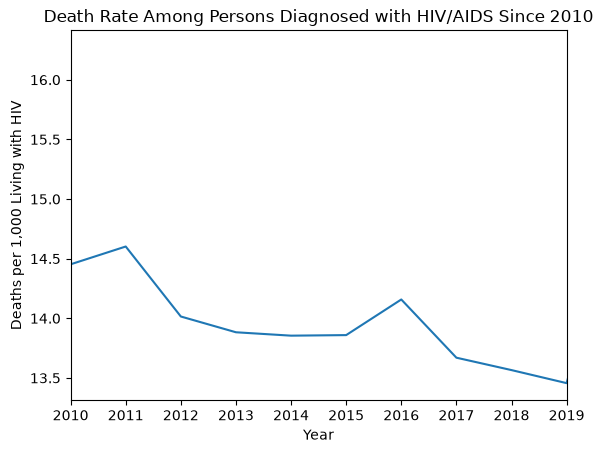

In [ ]:
deaths_by_year = combined[combined.Category == 'Race/Ethnicity'].groupby('Year')[['Count_Living','Count_Deaths']].sum() #picking one category to look at trends over time, since the other categories are not mutually exclusive
deaths_over_time = by_year.Count_Deaths / by_year.Count_Living * 1000

ax = deaths_over_time.plot.line(title='Death Rate Among Persons Diagnosed with HIV/AIDS (2010-2019' #leaving out 2020 because of COVID-19
ax.set_ylabel('Deaths per 1,000 Living with HIV')
ax.set_xlim(2010,2019)
plt.show()